# Treinando uma Rede Neural com PyTorch

Na aula de backpropagation, fizemos **uma iteração de treino à mão** em uma rede pequena (2 entradas, 2 neurônios ocultos, 1 saída): o forward pass calculou a previsão e a loss, o backward pass aplicou a regra da cadeia de trás para frente para obter o gradiente de cada peso, e um passo de gradiente descendente atualizou os pesos.

Fazer isso à mão para nove parâmetros já dá trabalho. Redes reais têm milhares ou milhões de parâmetros, e o treino repete essa iteração milhares de vezes. Neste notebook, vamos deixar o computador fazer as contas usando o **PyTorch**, uma das bibliotecas mais usadas para redes neurais.

O roteiro é:

1. **Tensores**: a estrutura de dados do PyTorch, e como ela calcula gradientes sozinha.
2. **Dados em tensores**: um dataset de classificação não linear.
3. **Batches**: o que são, por que precisamos deles e a relação com o SGD.
4. **O modelo, a loss e o otimizador.**
5. **O loop de treinamento, passo a passo.**
6. **O treino completo e a avaliação.**
7. **O tamanho do batch na prática.**

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

%matplotlib inline

np.random.seed(42)
torch.manual_seed(42)
print("Versão do PyTorch:", torch.__version__)

Versão do PyTorch: 2.8.0


---
## 1. O que é um tensor?

Um **tensor** é a estrutura de dados básica do PyTorch. Na prática, é um array de números com várias dimensões, muito parecido com um array do NumPy. O número de dimensões é chamado de *ordem* (ou *rank*) do tensor:

| Ordem | Nome | Exemplo em ML |
|---|---|---|
| 0 | escalar | o valor da loss |
| 1 | vetor | uma observação $\mathbf{x}^{(i)}$ com $p$ features |
| 2 | matriz | um dataset $\mathbf{X}$ com $n$ linhas e $p$ colunas |
| 3 ou mais | tensor | um lote de imagens: (imagens, altura, largura) |

A diferença para o NumPy está em dois recursos extras: um tensor pode ser processado na **GPU**, e o PyTorch consegue **calcular gradientes automaticamente** a partir das operações feitas com tensores. Esse segundo recurso é exatamente o backpropagation que vimos em aula.

In [2]:
escalar = torch.tensor(3.5)
vetor = torch.tensor([1.0, 2.0, 3.0])
matriz = torch.tensor([[1.0, 2.0], [3.0, 4.0], [5.0, 6.0]])
tensor_3d = torch.zeros(2, 3, 4)

for nome, t in [("escalar", escalar), ("vetor", vetor),
                ("matriz", matriz), ("tensor 3D", tensor_3d)]:
    print(f"{nome:10s} ndim = {t.ndim}   shape = {tuple(t.shape)}")

escalar    ndim = 0   shape = ()
vetor      ndim = 1   shape = (3,)
matriz     ndim = 2   shape = (3, 2)
tensor 3D  ndim = 3   shape = (2, 3, 4)


### 1.1 Do NumPy para o PyTorch

Os dados quase sempre começam como arrays do NumPy (ou tabelas do pandas). A conversão é direta. Um detalhe importante é o **tipo numérico** (`dtype`): o NumPy usa `float64` por padrão, enquanto as redes neurais do PyTorch trabalham com `float32`. Por isso convertemos explicitamente.

In [3]:
a_numpy = np.array([[0.5, 1.5], [2.0, -1.0]])
a_torch = torch.tensor(a_numpy)

print("dtype vindo do NumPy:", a_torch.dtype)
a_torch = a_torch.float()          # converte para float32
print("dtype depois de .float():", a_torch.dtype)
print(a_torch)

# E o caminho de volta, útil para gráficos:
print("De volta ao NumPy:", type(a_torch.numpy()))

dtype vindo do NumPy: torch.float64
dtype depois de .float(): torch.float32
tensor([[ 0.5000,  1.5000],
        [ 2.0000, -1.0000]])
De volta ao NumPy: <class 'numpy.ndarray'>


### 1.2 Operações: uma camada da rede é uma multiplicação de matrizes

As operações seguem a mesma lógica do NumPy. A mais importante para redes neurais é a multiplicação de matrizes, escrita com `@`. Nos slides, a entrada de um neurônio oculto era $z_{j,in} = \mathbf{W}_j^\top \mathbf{x} + b_j$. Com várias observações empilhadas em uma matriz $\mathbf{X}$ ($n \times p$) e vários neurônios de uma vez, a camada inteira vira uma única conta:

$$\mathbf{Z}_{in} = \mathbf{X}\mathbf{W} + \mathbf{b},$$

em que $\mathbf{W}$ tem uma coluna por neurônio e o vetor $\mathbf{b}$ é somado a cada linha (isso se chama *broadcasting*).

In [4]:
X_exemplo = torch.randn(4, 2)       # 4 observações, 2 features
W_exemplo = torch.randn(2, 3)       # 2 entradas -> 3 neurônios
b_exemplo = torch.randn(3)          # um bias por neurônio

Z_in = X_exemplo @ W_exemplo + b_exemplo
print("shape de X:", tuple(X_exemplo.shape))
print("shape de W:", tuple(W_exemplo.shape))
print("shape de Z_in:", tuple(Z_in.shape), "-> uma linha por observação, uma coluna por neurônio")

shape de X: (4, 2)
shape de W: (2, 3)
shape de Z_in: (4, 3) -> uma linha por observação, uma coluna por neurônio


### 1.3 Gradientes automáticos (*autograd*)

Se marcarmos um tensor com `requires_grad=True`, o PyTorch passa a **registrar todas as operações** feitas com ele, montando o grafo computacional, como o desenho da rede nos slides. Ao chamar `.backward()` em um resultado escalar, ele percorre esse grafo de trás para frente aplicando a regra da cadeia e guarda a derivada de cada tensor no atributo `.grad`.

Um exemplo mínimo: para $f(w) = w^2$, sabemos que $f'(w) = 2w$, então em $w = 3$ a derivada é $6$.

In [5]:
w = torch.tensor(3.0, requires_grad=True)
f = w ** 2          # forward: o PyTorch registra a operação
f.backward()        # backward: aplica a regra da cadeia

print("f(w) =", f.item())
print("df/dw calculado pelo PyTorch:", w.grad.item())
print("df/dw pela fórmula 2w:       ", 2 * w.item())

f(w) = 9.0
df/dw calculado pelo PyTorch: 6.0
df/dw pela fórmula 2w:        6.0


### 1.4 O exemplo dos slides, agora no PyTorch

Vamos refazer a iteração dos slides de backpropagation: rede 2–2–1, ativação logística $\sigma$ nas duas camadas, observação $\mathbf{x} = (1, 0)^\top$ com $y = 1$, loss $L(y, f(\mathbf{x})) = \tfrac12 (y - f_{out})^2$ e learning rate $\alpha = 0.5$. Os pesos são os mesmos dos slides; $W_{ij}$ liga a entrada $x_i$ ao neurônio oculto $z_j$.

In [6]:
x = torch.tensor([1.0, 0.0])
y = torch.tensor(1.0)

W = torch.tensor([[-0.07, 0.94],
                  [ 0.22, 0.46]], requires_grad=True)
b = torch.tensor([-0.46, 0.10], requires_grad=True)
u = torch.tensor([-0.22, 0.58], requires_grad=True)
c = torch.tensor(0.78, requires_grad=True)

# Forward pass, com os mesmos nomes dos slides
z_in = x @ W + b
z_out = torch.sigmoid(z_in)
f_in = z_out @ u + c
f_out = torch.sigmoid(f_in)
loss = 0.5 * (y - f_out) ** 2

print("z_in  =", z_in.detach().numpy().round(4))
print("z_out =", z_out.detach().numpy().round(4))
print(f"f_in  = {f_in.item():.4f}   f_out = {f_out.item():.4f}   loss = {loss.item():.4f}")

z_in  = [-0.53  1.04]
z_out = [0.3705 0.7388]
f_in  = 1.1270   f_out = 0.7553   loss = 0.0299


Agora, em vez de calcular as derivadas à mão, basta uma linha: `loss.backward()`. Comparamos com os dois gradientes calculados nos slides, $\partial L / \partial u_1 \approx -0.0171$ e $\partial L / \partial W_{11} \approx 0.0024$.

In [7]:
loss.backward()

print(f"dL/du1  (PyTorch) = {u.grad[0].item():.4f}    (slides: -0.0171)")
print(f"dL/dW11 (PyTorch) = {W.grad[0, 0].item():.4f}    (slides:  0.0024)")
print()
print("Gradiente de W inteiro:")
print(W.grad.numpy().round(4))

dL/du1  (PyTorch) = -0.0168    (slides: -0.0171)
dL/dW11 (PyTorch) = 0.0023    (slides:  0.0024)

Gradiente de W inteiro:
[[ 0.0023 -0.0051]
 [ 0.      0.    ]]


Os valores batem com os slides, a menos de pequenas diferenças: nos slides, a soma de $f_{in}$ foi arredondada para $1.1122$, enquanto o valor exato é $1.1271$. Repare também que a **segunda linha** do gradiente de $\mathbf{W}$ é zero: são os pesos $W_{21}$ e $W_{22}$, que saem de $x_2 = 0$. Como vimos em aula, um peso só recebe gradiente quando o sinal que passa por ele é diferente de zero.

Para fechar a iteração, fazemos o passo de gradiente descendente $\theta^{[t+1]} = \theta^{[t]} - \alpha \cdot \nabla_\theta L$. O bloco `torch.no_grad()` avisa ao PyTorch que essa atualização não faz parte do grafo e não deve ser registrada.

In [8]:
alpha = 0.5
with torch.no_grad():
    for p in (W, b, u, c):
        p -= alpha * p.grad

    nova_previsao = torch.sigmoid(torch.sigmoid(x @ W + b) @ u + c)
    nova_loss = 0.5 * (y - nova_previsao) ** 2

print(f"Antes:  f_out = {f_out.item():.4f}, loss = {loss.item():.4f}")
print(f"Depois: f_out = {nova_previsao.item():.4f}, loss = {nova_loss.item():.4f}")

Antes:  f_out = 0.7553, loss = 0.0299
Depois: f_out = 0.7624, loss = 0.0282


A loss caiu, exatamente como no último slide da aula. Tudo o que fizemos à mão em vinte slides coube em poucas linhas. O resto do notebook usa as ferramentas do PyTorch que automatizam ainda mais esse processo para uma rede e um dataset de verdade.

---
## 2. Os dados em tensores

Vamos usar o dataset `make_moons` do scikit-learn: duas classes em formato de meia-lua, entrelaçadas. Assim como o XOR dos slides, as classes **não são linearmente separáveis**: nenhuma reta separa bem as duas luas, então um modelo linear não basta e precisamos de uma camada oculta.

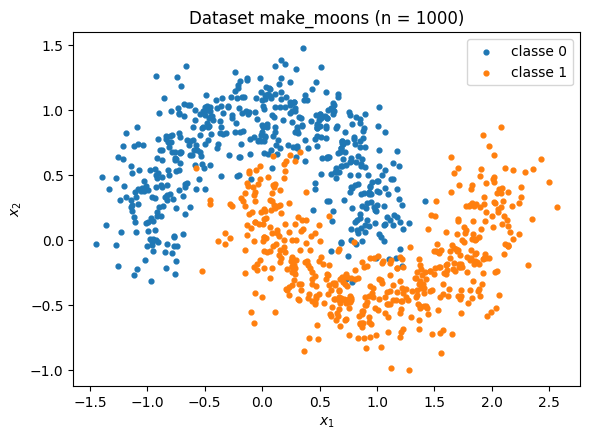

In [9]:
X_np, y_np = make_moons(n_samples=1000, noise=0.2, random_state=42)

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.scatter(X_np[y_np == 0, 0], X_np[y_np == 0, 1], s=12, label="classe 0")
ax.scatter(X_np[y_np == 1, 0], X_np[y_np == 1, 1], s=12, label="classe 1")
ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")
ax.set_title("Dataset make_moons (n = 1000)")
ax.legend()
plt.tight_layout(); plt.show()

Separamos 80% para treino e 20% para teste e convertemos tudo para tensores `float32`. O target vira uma **matriz coluna** de shape $(n, 1)$, porque a rede terá uma saída por observação e a loss do PyTorch espera que previsão e target tenham o mesmo shape.

In [10]:
X_train_np, X_test_np, y_train_np, y_test_np = train_test_split(
    X_np, y_np, test_size=0.2, random_state=42, stratify=y_np)

X_train = torch.tensor(X_train_np, dtype=torch.float32)
y_train = torch.tensor(y_train_np, dtype=torch.float32).unsqueeze(1)  # (n,) -> (n, 1)
X_test = torch.tensor(X_test_np, dtype=torch.float32)
y_test = torch.tensor(y_test_np, dtype=torch.float32).unsqueeze(1)

print("X_train:", tuple(X_train.shape), X_train.dtype)
print("y_train:", tuple(y_train.shape), y_train.dtype)
print("X_test: ", tuple(X_test.shape))
print("Primeiras 3 observações de treino:")
print(torch.cat([X_train[:3], y_train[:3]], dim=1))

X_train: (800, 2) torch.float32
y_train: (800, 1) torch.float32
X_test:  (200, 2)
Primeiras 3 observações de treino:
tensor([[ 0.2197, -0.2217,  1.0000],
        [ 0.4783,  0.7243,  0.0000],
        [ 2.1761,  0.2620,  1.0000]])


---
## 3. Batches: o que são e por que precisamos deles

Queremos minimizar o risco empírico com gradiente descendente:

$$\mathcal{R}_{\text{emp}}(\theta) = \frac{1}{n}\sum_{i=1}^{n} L\left(y^{(i)}, f(\mathbf{x}^{(i)} \mid \theta)\right).$$

O gradiente de $\mathcal{R}_{\text{emp}}$ é a **média dos gradientes de todas as $n$ observações**. Há três formas de usar os dados a cada passo de atualização:

- **Gradiente descendente (completo)**: usa todas as $n$ observações para calcular o gradiente e dá um passo. É o gradiente exato, mas cada passo custa uma passada inteira pelos dados.
- **SGD com uma observação**: usa uma única observação por passo, como fizemos nos slides de backpropagation. Cada passo é barato, mas o gradiente é muito ruidoso.
- **SGD com mini-batch**: usa um pequeno grupo de $B$ observações, o **batch** (por exemplo, $B = 32$). É o meio-termo, e é o que se usa na prática.

Com um batch $\mathcal{B}$, o gradiente usado no passo é uma **estimativa** do gradiente verdadeiro:

$$\nabla_\theta \mathcal{R}_{\text{emp}}(\theta) \;\approx\; \frac{1}{|\mathcal{B}|} \sum_{i \in \mathcal{B}} \nabla_\theta L\left(y^{(i)}, f(\mathbf{x}^{(i)} \mid \theta)\right).$$

É uma média sobre uma amostra das observações em vez de sobre todas. Quanto maior o batch, melhor a estimativa, e mais caro cada passo.

Por que não usar sempre todos os dados? Primeiro, por **memória**: em datasets reais (milhões de imagens ou textos), não cabe tudo na memória da GPU de uma vez. Segundo, por **velocidade de aprendizado**: com batches, damos muitos passos de atualização a cada passada pelos dados, em vez de um só. Terceiro, por **eficiência do hardware**: a GPU processa um batch inteiro em paralelo quase no mesmo tempo que processaria uma única observação, por isso batches de dezenas ou centenas de observações aproveitam melhor a máquina do que $B = 1$.

Dois termos aparecem o tempo todo:

- **iteração**: um passo de atualização, com um batch;
- **época**: uma passada completa por todas as observações de treino. Com $n$ observações e batches de tamanho $B$, uma época tem $\lceil n / B \rceil$ iterações.

### 3.1 Montando batches à mão

Antes de usar as ferramentas do PyTorch, vamos ver o que um batch é de fato: embaralhamos os índices das observações e cortamos em pedaços de tamanho $B$.

In [11]:
B = 32
n_train = X_train.shape[0]
indices = torch.randperm(n_train)          # embaralha 0, 1, ..., n-1

tamanhos = []
for inicio in range(0, n_train, B):
    idx_batch = indices[inicio:inicio + B]
    X_batch = X_train[idx_batch]
    tamanhos.append(len(idx_batch))

print(f"n = {n_train}, B = {B} -> {len(tamanhos)} batches por época")
print("Tamanhos dos batches:", tamanhos)
print("Shape do último X_batch:", tuple(X_batch.shape))

n = 800, B = 32 -> 25 batches por época
Tamanhos dos batches: [32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32]
Shape do último X_batch: (32, 2)


Aqui todos os batches têm 32 observações porque $800 = 25 \times 32$. Com outro $n$, o último batch ficaria menor, com as observações que sobrassem. O embaralhamento a cada época faz com que os batches sejam diferentes de uma época para a outra, o que evita que o modelo veja sempre os mesmos grupos na mesma ordem.

### 3.2 `TensorDataset` e `DataLoader`

O PyTorch faz exatamente esse trabalho com duas classes. O `TensorDataset` junta features e target, de modo que cada observação $i$ seja o par $(\mathbf{x}^{(i)}, y^{(i)})$. O `DataLoader` embaralha e entrega os batches, um por vez, dentro de um `for`.

In [12]:
train_dataset = TensorDataset(X_train, y_train)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)

print("Observações no dataset:", len(train_dataset))
print("Batches por época:      ", len(train_loader))

X_batch, y_batch = next(iter(train_loader))     # pega o primeiro batch
print("Shape de X_batch:", tuple(X_batch.shape))
print("Shape de y_batch:", tuple(y_batch.shape))

Observações no dataset: 800
Batches por época:       25
Shape de X_batch: (32, 2)
Shape de y_batch: (32, 1)


---
## 4. O modelo, a loss e o otimizador

### 4.1 O modelo

Montamos a rede com `nn.Sequential`, que empilha as camadas na ordem do forward pass:

- `nn.Linear(2, 16)`: a camada oculta, que calcula $\mathbf{Z}_{in} = \mathbf{X}\mathbf{W} + \mathbf{b}$ para 16 neurônios;
- `nn.ReLU()`: a ativação dos neurônios ocultos, $\max(0, z)$;
- `nn.Linear(16, 1)`: a camada de saída, que calcula $f_{in}$.

Nos slides usamos a logística como ativação oculta. Aqui usamos a **ReLU**, que é a escolha mais comum hoje e treina mais rápido neste problema. Trocar `nn.ReLU()` por `nn.Sigmoid()` reproduz a rede dos slides e é um bom exercício.

In [13]:
torch.manual_seed(42)
model = nn.Sequential(
    nn.Linear(2, 16),
    nn.ReLU(),
    nn.Linear(16, 1),
)
print(model)

n_params = sum(p.numel() for p in model.parameters())
print("\nNúmero de parâmetros:", n_params)
for nome, p in model.named_parameters():
    print(f"  {nome:10s} shape = {tuple(p.shape)}")

Sequential(
  (0): Linear(in_features=2, out_features=16, bias=True)
  (1): ReLU()
  (2): Linear(in_features=16, out_features=1, bias=True)
)

Número de parâmetros: 65
  0.weight   shape = (16, 2)
  0.bias     shape = (16,)
  2.weight   shape = (1, 16)
  2.bias     shape = (1,)


São $2 \cdot 16 + 16 = 48$ parâmetros na camada oculta e $16 + 1 = 17$ na saída, 65 no total. Um detalhe de convenção: o `nn.Linear` guarda a matriz de pesos com shape (saídas, entradas), isto é, transposta em relação ao $\mathbf{W}$ que usamos acima. Isso não muda nada na conta, só na forma de armazenar.

Repare também que a rede **não tem ativação na saída**: ela devolve $f_{in}$, um número real qualquer (o *log-odds*). A sigmoid fica dentro da loss, como explicamos a seguir.

### 4.2 A loss

Nos slides, usamos a loss $L2$ para simplificar as contas. Para classificação, o padrão é a **log-loss** (entropia cruzada binária), a mesma da regressão logística. O PyTorch oferece `nn.BCEWithLogitsLoss`, que recebe $f_{in}$, aplica a sigmoid internamente e calcula a log-loss média do batch. Juntar as duas etapas é mais estável numericamente do que aplicar a sigmoid e depois a log-loss separadamente.

In [14]:
loss_fn = nn.BCEWithLogitsLoss()

with torch.no_grad():
    f_in_batch = model(X_batch)                 # saída da rede para o batch
    print("Shape da saída da rede:", tuple(f_in_batch.shape))
    print("Primeiras saídas (f_in):", f_in_batch[:4, 0].numpy().round(3))
    print("Probabilidades (sigmoid):", torch.sigmoid(f_in_batch[:4, 0]).numpy().round(3))
    print("Loss no batch:", round(loss_fn(f_in_batch, y_batch).item(), 4))

Shape da saída da rede: (32, 1)
Primeiras saídas (f_in): [ 0.191  0.172 -0.032  0.57 ]
Probabilidades (sigmoid): [0.548 0.543 0.492 0.639]
Loss no batch: 0.6373


Com pesos aleatórios, as probabilidades ficam perto de $0.5$ e a loss fica na mesma faixa de $\log 2 \approx 0.69$, que é a loss de quem prevê $0.5$ para todo mundo: a rede ainda não sabe nada.

### 4.3 O otimizador

O otimizador guarda a lista de parâmetros e aplica a regra de atualização. Usamos `torch.optim.SGD`, que faz exatamente $\theta^{[t+1]} = \theta^{[t]} - \alpha \cdot \nabla_\theta L$, com $\alpha$ = `lr` (learning rate).

In [15]:
optimizer = torch.optim.SGD(model.parameters(), lr=0.5)
print(optimizer)

SGD (
Parameter Group 0
    dampening: 0
    differentiable: False
    foreach: None
    fused: None
    lr: 0.5
    maximize: False
    momentum: 0
    nesterov: False
    weight_decay: 0
)


---
## 5. O loop de treinamento, passo a passo

Toda iteração de treino no PyTorch tem os mesmos cinco passos. Vamos executá-los **uma única vez**, em células separadas, para ver o que cada um faz. Depois juntamos tudo em um loop.

### Passo 1: pegar um batch

In [16]:
X_batch, y_batch = next(iter(train_loader))
print("X_batch:", tuple(X_batch.shape), " y_batch:", tuple(y_batch.shape))

X_batch: (32, 2)  y_batch: (32, 1)


### Passo 2: forward pass

A rede recebe o batch e devolve uma saída por observação. Por trás da linha `model(X_batch)`, acontecem as mesmas contas dos slides ($z_{in}$, $z_{out}$, $f_{in}$), para as 32 observações de uma vez. O PyTorch registra cada operação para poder voltar depois.

In [17]:
f_in_batch = model(X_batch)
print("Saída da rede:", tuple(f_in_batch.shape))

Saída da rede: (32, 1)


### Passo 3: calcular a loss

A loss compara as saídas com os targets e devolve **um único número**: a média da log-loss sobre o batch. É desse número que o backward pass vai partir.

In [18]:
loss = loss_fn(f_in_batch, y_batch)
print(f"Loss do batch: {loss.item():.4f}")

Loss do batch: 0.6354


### Passo 4: zerar os gradientes e fazer o backward pass

`loss.backward()` é o backpropagation: percorre o grafo de trás para frente e guarda em `.grad` a derivada da loss em relação a **cada** parâmetro da rede.

Antes dele vem `optimizer.zero_grad()`. O PyTorch **soma** cada novo gradiente ao que já está em `.grad`, em vez de substituir. Se não zerarmos, o gradiente da iteração atual se misturaria com o das anteriores. Esquecer essa linha é um dos erros mais comuns ao escrever um loop de treino.

In [19]:
optimizer.zero_grad()
loss.backward()

peso = model[0].weight          # pesos da camada oculta
print("Shape do gradiente:", tuple(peso.grad.shape), "(mesmo shape do peso)")
print("Gradiente dos 3 primeiros pesos:", peso.grad[:3, 0].numpy().round(4))

Shape do gradiente: (16, 2) (mesmo shape do peso)
Gradiente dos 3 primeiros pesos: [-0.0308  0.0115  0.0036]


### Passo 5: atualizar os pesos

`optimizer.step()` aplica $\theta^{[t+1]} = \theta^{[t]} - \alpha \cdot \nabla_\theta L$ a todos os parâmetros. Vamos conferir a conta em um peso: guardamos o valor antes, atualizamos e comparamos com a fórmula.

In [20]:
antes = peso[0, 0].item()
gradiente = peso.grad[0, 0].item()

optimizer.step()

depois = peso[0, 0].item()
print(f"Peso antes:              {antes:.6f}")
print(f"Gradiente:               {gradiente:.6f}")
print(f"Peso depois (PyTorch):   {depois:.6f}")
print(f"antes - 0.5 * gradiente: {antes - 0.5 * gradiente:.6f}")

Peso antes:              0.540610
Gradiente:               -0.030833
Peso depois (PyTorch):   0.556027
antes - 0.5 * gradiente: 0.556027


Por fim, conferimos que a loss **no mesmo batch** diminuiu depois do passo, como no último slide da aula de backpropagation:

In [21]:
with torch.no_grad():
    loss_depois = loss_fn(model(X_batch), y_batch)
print(f"Loss do batch antes do passo:  {loss.item():.4f}")
print(f"Loss do batch depois do passo: {loss_depois.item():.4f}")

Loss do batch antes do passo:  0.6354
Loss do batch depois do passo: 0.5515


Resumindo os cinco passos e a correspondência com a aula:

| Passo | Código | Nos slides de backpropagation |
|---|---|---|
| 1 | `for X_batch, y_batch in train_loader:` | escolher a observação $\mathbf{x} = (1, 0)^\top$ |
| 2 | `f_in = model(X_batch)` | forward pass: $z_{in}$, $z_{out}$, $f_{in}$, $f_{out}$ |
| 3 | `loss = loss_fn(f_in, y_batch)` | calcular $L(y, f(\mathbf{x}))$ |
| 4 | `optimizer.zero_grad()` e `loss.backward()` | backward pass: regra da cadeia para cada peso |
| 5 | `optimizer.step()` | $\theta^{[\text{novo}]} = \theta^{[\text{velho}]} - \alpha \cdot \partial L / \partial \theta$ |

---
## 6. O treino completo

Agora repetimos os cinco passos para todos os batches (uma época) e repetimos as épocas várias vezes. Ao fim de cada época, calculamos a loss em todo o conjunto de treino e no de teste, para acompanhar o aprendizado.

Começamos de um modelo novo, para que o treino não dependa da iteração isolada que fizemos acima.

In [22]:
def criar_modelo():
    torch.manual_seed(42)
    return nn.Sequential(nn.Linear(2, 16), nn.ReLU(), nn.Linear(16, 1))

model = criar_modelo()
optimizer = torch.optim.SGD(model.parameters(), lr=0.5)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True,
                          generator=torch.Generator().manual_seed(42))
n_epocas = 100
print(f"{n_epocas} épocas x {len(train_loader)} batches = "
      f"{n_epocas * len(train_loader)} iterações de SGD")

100 épocas x 25 batches = 2500 iterações de SGD


In [23]:
historico_treino, historico_teste = [], []

for epoca in range(n_epocas):
    for X_batch, y_batch in train_loader:          # passo 1
        f_in = model(X_batch)                       # passo 2
        loss = loss_fn(f_in, y_batch)               # passo 3
        optimizer.zero_grad()                       # passo 4
        loss.backward()
        optimizer.step()                            # passo 5

    with torch.no_grad():                           # avaliação, sem gradientes
        historico_treino.append(loss_fn(model(X_train), y_train).item())
        historico_teste.append(loss_fn(model(X_test), y_test).item())

    if epoca % 20 == 0 or epoca == n_epocas - 1:
        print(f"época {epoca:3d}: loss treino = {historico_treino[-1]:.4f}, "
              f"loss teste = {historico_teste[-1]:.4f}")

época   0: loss treino = 0.3337, loss teste = 0.2668
época  20: loss treino = 0.1294, loss teste = 0.0804
época  40: loss treino = 0.0846, loss teste = 0.0495
época  60: loss treino = 0.0779, loss teste = 0.0457
época  80: loss treino = 0.0781, loss teste = 0.0450
época  99: loss treino = 0.0734, loss teste = 0.0433


O núcleo do treino são as seis linhas dentro do `for` interno, que são os cinco passos da seção anterior. Todo o resto (épocas, histórico, impressão) é organização.

A loss de teste ficou um pouco abaixo da de treino. Isso não é um erro: com um dataset pequeno e ruidoso, o conjunto de teste pode, por acaso, ter menos pontos na região em que as luas se sobrepõem. O que importa é que as duas curvas caem juntas, sem sinal de overfitting.

Na avaliação, usamos `torch.no_grad()`: como não vamos atualizar nada, não precisamos que o PyTorch registre as operações, o que economiza memória e tempo.

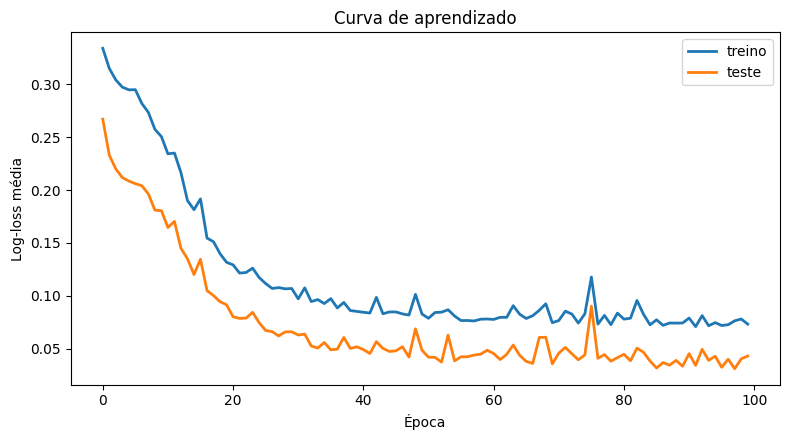

In [24]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(historico_treino, label="treino", linewidth=2)
ax.plot(historico_teste, label="teste", linewidth=2)
ax.set_xlabel("Época")
ax.set_ylabel("Log-loss média")
ax.set_title("Curva de aprendizado")
ax.legend()
plt.tight_layout(); plt.show()

### 6.1 Avaliação no conjunto de teste

Para classificar, usamos a regra de sempre: classe 1 se a probabilidade prevista for maior que $0.5$, o que equivale a $f_{in} > 0$ (a sigmoid de zero é $0.5$).

In [25]:
with torch.no_grad():
    prob_teste = torch.sigmoid(model(X_test))
    pred_teste = (prob_teste > 0.5).float()

accuracy = (pred_teste == y_test).float().mean().item()
print(f"Accuracy no teste: {accuracy:.3f}")
print("Probabilidades das 5 primeiras observações de teste:", prob_teste[:5, 0].numpy().round(3))
print("Classes verdadeiras:                              ", y_test[:5, 0].numpy())

Accuracy no teste: 0.985
Probabilidades das 5 primeiras observações de teste: [0.998 0.    0.    0.003 0.991]
Classes verdadeiras:                               [1. 0. 0. 0. 1.]


### 6.2 A fronteira de decisão

Para ver o que a rede aprendeu, calculamos a probabilidade prevista em uma grade de pontos do plano e pintamos as regiões. A fronteira de decisão é a curva em que a probabilidade vale $0.5$. Diferente de um modelo linear, ela acompanha o formato das luas.

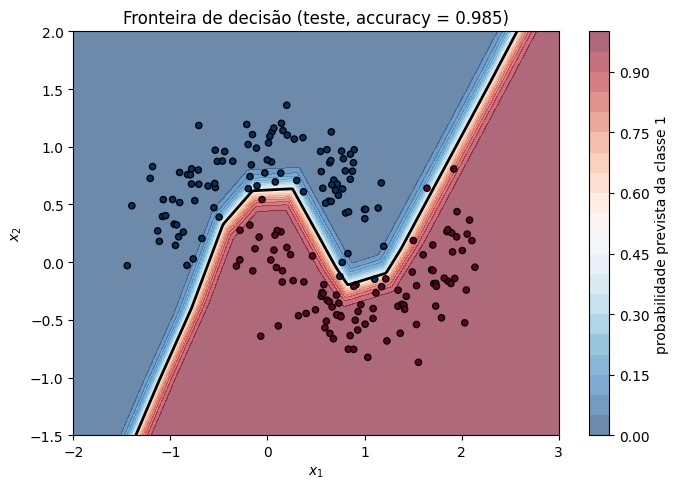

In [26]:
xx, yy = np.meshgrid(np.linspace(-2, 3, 300), np.linspace(-1.5, 2, 300))
grade = torch.tensor(np.column_stack([xx.ravel(), yy.ravel()]), dtype=torch.float32)
with torch.no_grad():
    prob_grade = torch.sigmoid(model(grade)).numpy().reshape(xx.shape)

fig, ax = plt.subplots(figsize=(7, 5))
cont = ax.contourf(xx, yy, prob_grade, levels=20, cmap="RdBu_r", alpha=0.6)
ax.contour(xx, yy, prob_grade, levels=[0.5], colors="black", linewidths=2)
ax.scatter(X_test_np[:, 0], X_test_np[:, 1], c=y_test_np, cmap="RdBu_r",
           edgecolors="k", s=20)
fig.colorbar(cont, label="probabilidade prevista da classe 1")
ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")
ax.set_title(f"Fronteira de decisão (teste, accuracy = {accuracy:.3f})")
plt.tight_layout(); plt.show()

---
## 7. O tamanho do batch na prática

### 7.1 O batch estima o gradiente

Dissemos que o gradiente de um batch é uma estimativa do gradiente verdadeiro (calculado com todas as observações). Vamos medir isso. Fixamos um modelo recém-criado, calculamos o gradiente com as 800 observações de treino e, para vários tamanhos de batch, sorteamos 200 batches e medimos o quanto o gradiente de cada um se parece com o verdadeiro.

Como medida, usamos a **similaridade de cosseno** entre os dois vetores de gradiente: vale $1$ quando apontam exatamente na mesma direção e $0$ quando são perpendiculares.

In [27]:
def gradiente(modelo, X, y):
    modelo.zero_grad()
    loss_fn(modelo(X), y).backward()
    return torch.cat([p.grad.flatten() for p in modelo.parameters()])

modelo_fixo = criar_modelo()
g_verdadeiro = gradiente(modelo_fixo, X_train, y_train)

tamanhos_batch = [1, 4, 16, 64, 256]
similaridades = {}
for B in tamanhos_batch:
    sims = []
    for _ in range(200):
        idx = torch.randperm(n_train)[:B]
        g_batch = gradiente(modelo_fixo, X_train[idx], y_train[idx])
        sims.append(torch.cosine_similarity(g_batch, g_verdadeiro, dim=0).item())
    similaridades[B] = sims
    print(f"B = {B:3d}: similaridade média = {np.mean(sims):.3f}")

B =   1: similaridade média = 0.339
B =   4: similaridade média = 0.588
B =  16: similaridade média = 0.822
B =  64: similaridade média = 0.936
B = 256: similaridade média = 0.990


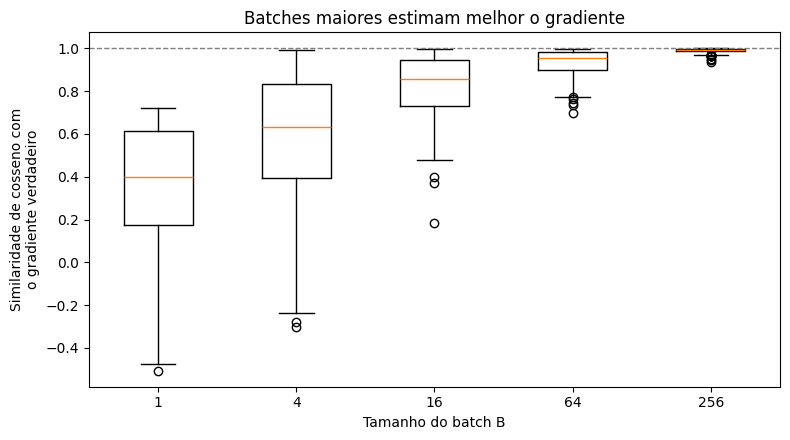

In [28]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.boxplot([similaridades[B] for B in tamanhos_batch],
           tick_labels=[str(B) for B in tamanhos_batch])
ax.axhline(1.0, color="gray", linestyle="--", linewidth=1)
ax.set_xlabel("Tamanho do batch B")
ax.set_ylabel("Similaridade de cosseno com\no gradiente verdadeiro")
ax.set_title("Batches maiores estimam melhor o gradiente")
plt.tight_layout(); plt.show()

Com $B = 1$, o gradiente de uma única observação muitas vezes aponta para uma direção bem diferente do gradiente verdadeiro, e às vezes até para o lado oposto (similaridade negativa). À medida que $B$ cresce, a estimativa fica cada vez mais próxima. É a mesma ideia de estimar uma média com uma amostra: quanto maior a amostra, menor a variação.

### 7.2 Mais passos ou passos melhores?

Batches menores dão passos mais ruidosos, mas dão **mais passos por época**. Vamos treinar o mesmo modelo por 30 épocas com três tamanhos de batch: $B = 1$ (SGD com uma observação, como nos slides), $B = 32$ (mini-batch) e $B = 800$ (todas as observações, ou seja, gradiente descendente completo). Para comparar de forma justa, usamos a mesma learning rate, $\alpha = 0.1$, nos três casos.

In [29]:
import time

def treinar(B, lr=0.1, n_epocas=30):
    modelo = criar_modelo()
    opt = torch.optim.SGD(modelo.parameters(), lr=lr)
    loader = DataLoader(train_dataset, batch_size=B, shuffle=True,
                        generator=torch.Generator().manual_seed(42))
    historico, inicio = [], time.time()
    for _ in range(n_epocas):
        for X_b, y_b in loader:
            opt.zero_grad()
            loss_fn(modelo(X_b), y_b).backward()
            opt.step()
        with torch.no_grad():
            historico.append(loss_fn(modelo(X_train), y_train).item())
    return historico, time.time() - inicio, len(loader) * n_epocas

resultados = {B: treinar(B) for B in [1, 32, 800]}
for B, (hist, tempo, passos) in resultados.items():
    print(f"B = {B:3d}: {passos:5d} passos, {tempo:4.1f} s, loss final = {hist[-1]:.4f}")

B =   1: 24000 passos,  3.4 s, loss final = 0.0830
B =  32:   750 passos,  0.2 s, loss final = 0.2834
B = 800:    30 passos,  0.1 s, loss final = 0.4330


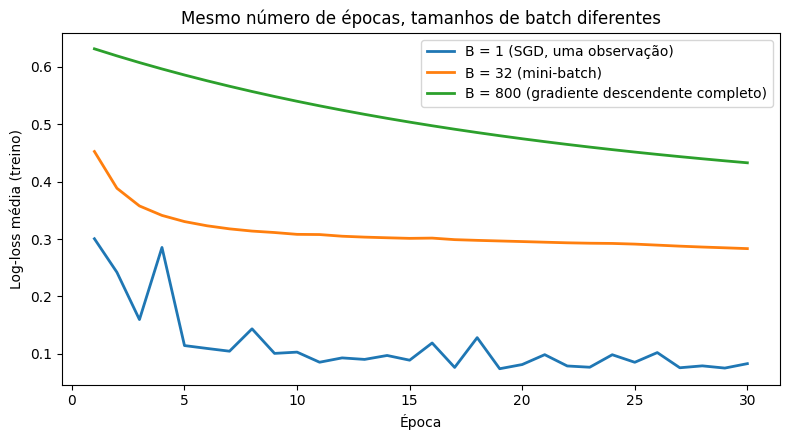

In [30]:
fig, ax = plt.subplots(figsize=(8, 4.5))
nomes = {1: "B = 1 (SGD, uma observação)", 32: "B = 32 (mini-batch)",
         800: "B = 800 (gradiente descendente completo)"}
for B, (hist, _, _) in resultados.items():
    ax.plot(range(1, len(hist) + 1), hist, label=nomes[B], linewidth=2)
ax.set_xlabel("Época")
ax.set_ylabel("Log-loss média (treino)")
ax.set_title("Mesmo número de épocas, tamanhos de batch diferentes")
ax.legend()
plt.tight_layout(); plt.show()

Medido em **épocas**, o batch pequeno aprende mais rápido, porque dá muito mais passos: com $B = 800$, são só 30 atualizações no total, contra 24 mil com $B = 1$. Mas cada passo com $B = 1$ é ruidoso, e o tempo de relógio é bem maior, porque processar uma observação por vez desperdiça o paralelismo do computador. O mini-batch fica no meio: passos razoavelmente bons, muitos por época e eficientes no hardware. Por isso é a escolha padrão na prática, com $B$ entre algumas dezenas e algumas centenas.

---
## 8. Resumo

| Conceito | No PyTorch | Ideia |
|---|---|---|
| Tensor | `torch.tensor(...)` | array com várias dimensões, que pode ir para a GPU e calcular gradientes |
| Autograd | `requires_grad=True`, `.backward()`, `.grad` | o backpropagation feito automaticamente |
| Batch | `DataLoader(..., batch_size=B, shuffle=True)` | grupo de $B$ observações usado em um passo |
| Época | o `for` externo | uma passada completa pelos dados de treino |
| Modelo | `nn.Sequential(nn.Linear, nn.ReLU, ...)` | o forward pass |
| Loss | `nn.BCEWithLogitsLoss()` | log-loss para classificação binária |
| Otimizador | `torch.optim.SGD(model.parameters(), lr=...)` | $\theta^{[t+1]} = \theta^{[t]} - \alpha \cdot \nabla_\theta L$ |

E o loop de treinamento, que é o mesmo para praticamente qualquer rede neural:

```python
for epoca in range(n_epocas):
    for X_batch, y_batch in train_loader:   # 1. pegar um batch
        f_in = model(X_batch)                # 2. forward pass
        loss = loss_fn(f_in, y_batch)        # 3. loss
        optimizer.zero_grad()                # 4. zerar gradientes...
        loss.backward()                      #    ...e backward pass
        optimizer.step()                     # 5. atualizar os pesos
```

O que mudou em relação aos slides de backpropagation não foi o algoritmo, mas quem faz as contas: o forward pass, a regra da cadeia e o passo de gradiente descendente são exatamente os mesmos, agora aplicados a um batch de observações de cada vez e repetidos milhares de vezes.